# FinGPT Assignment1: executed8B review

Llama only,300test rows per variant. The required second-model experiment remains incomplete by student decision. Personal HITL and Medium publication remain pending. Model-count and resource adaptations: Research_Report.pdf and REQUIREMENTS_CHECKLIST.md.

In [1]:
from pathlib import Path
import json,pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
metrics=json.loads((ROOT/'results/gpu_metrics.json').read_text())
display(pd.read_csv(ROOT/'results/gpu_metrics.csv'))

,architecture,total_count,valid_count,coverage,prediction_parse_failures,reference_parse_failures,bin_acc,mse,unconditional_direction_accuracy,model,...,label_direction_accuracy_all_rows,pros_rouge_scores_rouge1,pros_rouge_scores_rouge2,pros_rouge_scores_rougeL,cons_rouge_scores_rouge1,cons_rouge_scores_rouge2,cons_rouge_scores_rougeL,anal_rouge_scores_rouge1,anal_rouge_scores_rouge2,anal_rouge_scores_rougeL
0,Llama-3.1-8B,300,206,0.686667,94,3,0.466019,7.13835,0.32,base,...,0.320000,0.255971,0.070402,0.174650,0.218562,0.043354,0.144587,0.275303,0.066297,0.152229
1,Llama-3.1-8B,300,250,0.833333,48,3,0.492000,9.79200,0.41,lora,...,0.413333,0.369854,0.113463,0.220243,0.325135,0.088592,0.203379,0.381374,0.100747,0.202274


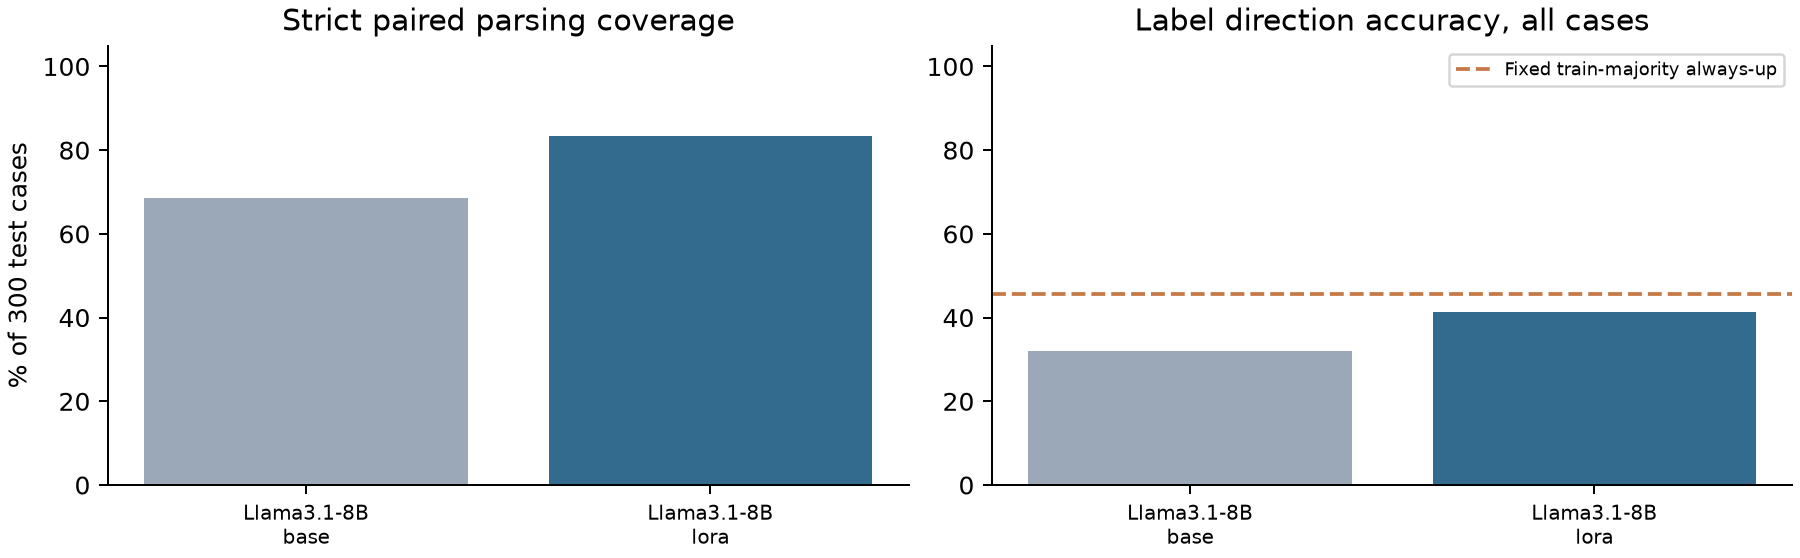

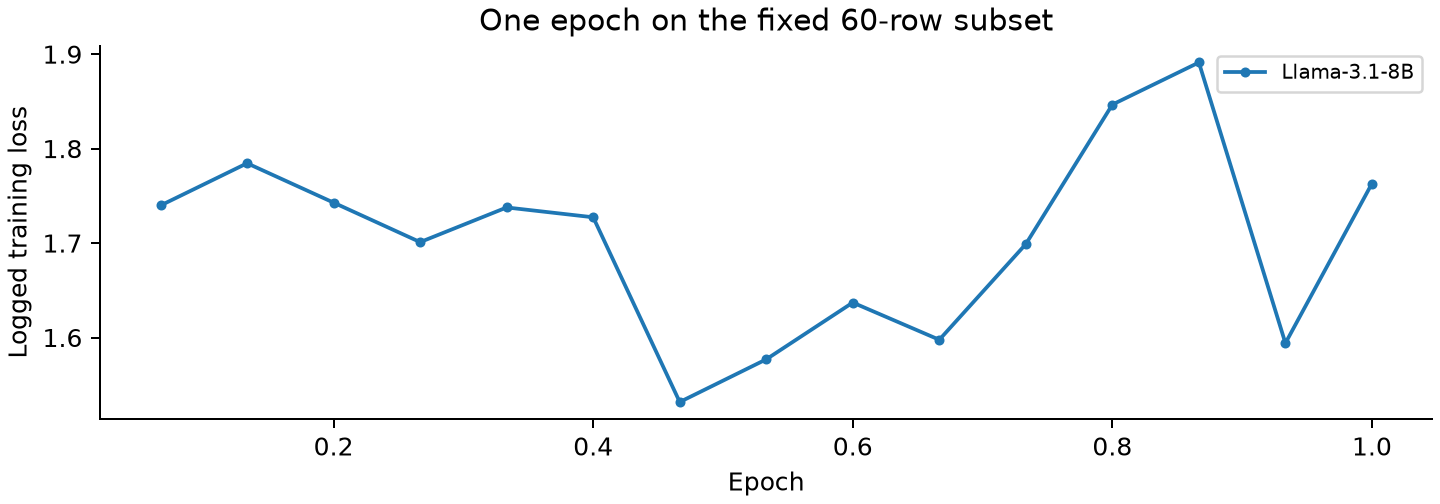

In [2]:
display(Image(filename=str(ROOT/'figures/gpu_coverage_accuracy.png')))
display(Image(filename=str(ROOT/'figures/gpu_training_loss.png')))

In [3]:
import subprocess,sys
for name in ['llama31_8b']:
    subprocess.run([sys.executable,str(ROOT/'cloud/validate_cloud_run.py'),str(ROOT/'cloud_runs'/name)],check=True)
    print(name,json.loads((ROOT/'cloud_runs'/name/'results/full_validation.json').read_text()))

{
  "run": "llama31_8b",
  "adapter_tensor_count": 448,
  "trainable_adapter_elements": 20971520,
  "adapter_values_finite": true,
  "adapter_sha256": "6287049cdfb37f278e36fff99a7e55d7d756fa5fad259457e587987ee5d72445",
  "frozen_hash_check": "first4096-element sample only; requires_grad audited during training",
  "test_checks": {
    "base": {
      "n": 300,
      "complete": true,
      "reference_identity_verified": true,
      "metrics_recomputed": true,
      "valid_count": 206
    },
    "lora": {
      "n": 300,
      "complete": true,
      "reference_identity_verified": true,
      "metrics_recomputed": true,
      "valid_count": 250
    }
  },
  "comparable_latency": {
    "matched_case_count": 0,
    "interpretation": "batch wall time divided by batch size is amortized throughput cost, not single-request latency"
  },
  "complete": true
}


llama31_8b {'run': 'llama31_8b', 'adapter_tensor_count': 448, 'trainable_adapter_elements': 20971520, 'adapter_values_finite': True, 'adapter_sha256': '6287049cdfb37f278e36fff99a7e55d7d756fa5fad259457e587987ee5d72445', 'frozen_hash_check': 'first4096-element sample only; requires_grad audited during training', 'test_checks': {'base': {'n': 300, 'complete': True, 'reference_identity_verified': True, 'metrics_recomputed': True, 'valid_count': 206}, 'lora': {'n': 300, 'complete': True, 'reference_identity_verified': True, 'metrics_recomputed': True, 'valid_count': 250}}, 'comparable_latency': {'matched_case_count': 0, 'interpretation': 'batch wall time divided by batch size is amortized throughput cost, not single-request latency'}, 'complete': True}


ROUGE is paired-reference F1 overlap. Missing timestamps, possible hindsight-conditioned teachers and pretraining overlap prevent prospective forecasting claims. Batch timings are amortized, not single-request latency.

In [4]:
review=pd.read_csv(ROOT/'HITL_review_Llama.csv')
display(review[['architecture','symbol','period','label','base_parse_valid','lora_parse_valid']])
print('Human review ratings must be provided by the student; no AI score is presented as human review.')

,architecture,symbol,period,label,base_parse_valid,lora_parse_valid
0,Llama-3.1-8B,AAPL,2024-02-25 to 2024-03-03,down by 1-2%,True,True
1,Llama-3.1-8B,AAPL,2024-04-28 to 2024-05-05,up by 0-1%,True,True
2,Llama-3.1-8B,CVX,2024-02-25 to 2024-03-03,down by 1-2%,True,False
3,Llama-3.1-8B,INTC,2024-04-28 to 2024-05-05,down by 4-5%,False,False
4,Llama-3.1-8B,PG,2024-02-25 to 2024-03-03,down by 1-2%,True,True
5,Llama-3.1-8B,WMT,2024-04-28 to 2024-05-05,down by 1-2%,False,True


Human review ratings must be provided by the student; no AI score is presented as human review.
